In [1]:
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"

In [2]:
import pandas as pd
import numpy as np

# 1. Read data

In [3]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
DATA_PATH_IMMUNOGENIC = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/immunogenic/per_length_per_kfold_split/' # windows

# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu

TARGET_PATH_TO_RESULTS = "experiment_results/low_iterations_training/"
# TARGET_PATH_TO_RESULTS = "experiment_results/backup/"


In [4]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")



per_allele_per_kfold_per_length_immunogenic_train = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "train", "immunogenic")
per_allele_per_kfold_per_length_immunogenic_test = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "test", "immunogenic")
per_allele_per_kfold_per_length_non_immunogenic_train = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "train", "nonimmunogenic")
per_allele_per_kfold_per_length_non_immunogenic_test = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "test", "nonimmunogenic")

ALLELES

['HLA-A*02:01']

# 2. Read models

In [6]:
from hmm_logic_methods import load_model, get_model_representation, get_all_paths_with_probs

In [7]:
split_num = 0
run_num = 0
target_length = 9
states= 18
selected_binding = f"{run_num}_run-{target_length}-{states}-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-{split_num}"
selected_immunogenic = f"{run_num}_run_imm-{target_length}-mer-of-[{selected_binding}]_model-HLA_A_02_01-{split_num}"

MODEL_PATH_USED_IMMUNOGENIC = f"{TARGET_PATH_TO_RESULTS}{selected_immunogenic}/"
MODEL_PATH_USED_BINNDING = f"{TARGET_PATH_TO_RESULTS}{selected_binding}/"

model_immunogenic = load_model(TARGET_PATH_TO_RESULTS, selected_immunogenic)
model_binding = load_model(TARGET_PATH_TO_RESULTS, selected_binding)

train_peptides_immunogenic = per_allele_per_kfold_per_length_immunogenic_train[ALLELES[0]][split_num][target_length]
train_peptides_non_immunogenic = per_allele_per_kfold_per_length_non_immunogenic_train[ALLELES[0]][split_num][target_length]

train_peptides_binding = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][split_num][target_length]
train_peptides_non_binding = per_allele_per_kfold_per_length_non_binders_train[ALLELES[0]][split_num][target_length]


test_peptides_immunogenic = per_allele_per_kfold_per_length_immunogenic_test[ALLELES[0]][split_num][target_length]
test_peptides_non_immunogenic = per_allele_per_kfold_per_length_non_immunogenic_test[ALLELES[0]][split_num][target_length]
test_peptides_binding = per_allele_per_kfold_per_length_binders_test[ALLELES[0]][split_num][target_length]
test_peptides_non_binding = per_allele_per_kfold_per_length_non_binders_test[ALLELES[0]][split_num][target_length]


# 3. Working with paths
## 3.1 Generate most probable paths, with probs

In [8]:
df_b_paths, edge_to_prob_b = get_all_paths_with_probs(model_binding)
df_i_paths, edge_to_prob_i = get_all_paths_with_probs(model_immunogenic)

Converting graph for model (0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-0) (Delete zero edges)
found 216 paths
Converting graph for model (0_run_imm-9-mer-of-[0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-0]_model-HLA_A_02_01-0) (Delete zero edges)
found 180 paths


## 3.2 Get representation DF for different data

In [136]:
generated_peptides_b = ["".join(model_binding.sample()) for i in range(10000)]
generated_peptides_i = ["".join(model_immunogenic.sample()) for i in range(10000)]

In [137]:
%%time
print("Train")
train_peptides_repr_data_b_model_b, path_to_index1 = get_model_representation(model_binding, set(train_peptides_binding), edge_value="log_probability")
train_peptides_repr_data_b_model_i, _ = get_model_representation(model_immunogenic, set(train_peptides_binding), edge_value="log_probability")
train_peptides_repr_data_i_model_b, path_to_index2 = get_model_representation(model_binding, set(train_peptides_immunogenic), edge_value="log_probability")
train_peptides_repr_data_i_model_i,_ = get_model_representation(model_immunogenic, set(train_peptides_immunogenic), edge_value="log_probability")

print("Test")
test_peptides_repr_data_b_model_b, path_to_index3 = get_model_representation(model_binding, set(test_peptides_binding), edge_value="log_probability")
test_peptides_repr_data_b_model_i, _ = get_model_representation(model_immunogenic, set(test_peptides_binding), edge_value="log_probability")
test_peptides_repr_data_i_model_b, path_to_index4 = get_model_representation(model_binding, set(test_peptides_immunogenic), edge_value="log_probability")
test_peptides_repr_data_i_model_i, _ = get_model_representation(model_immunogenic, set(test_peptides_immunogenic), edge_value="log_probability")

print("Generated")
generated_peptides_repr_data_b_model_b, _ = get_model_representation(model_binding, set(generated_peptides_b), edge_value="log_probability")
generated_peptides_repr_data_b_model_i, _ = get_model_representation(model_immunogenic, set(generated_peptides_b), edge_value="log_probability")
generated_peptides_repr_data_i_model_b, _ = get_model_representation(model_binding, set(generated_peptides_i), edge_value="log_probability")
generated_peptides_repr_data_i_model_i, _ = get_model_representation(model_immunogenic, set(generated_peptides_i), edge_value="log_probability")


#make dict for convinience
pivot_data_dict = dict()

dataset_keys = ['Train', 'Test', 'Generated']
source_keys = ['db', 'di']
model_keys = ['mb', 'mi']
for key in dataset_keys:
    pivot_data_dict[key] = dict()
    for s_key in source_keys:
        pivot_data_dict[key][s_key] = dict()
        
        
pivot_data_dict['Train']['db']['mb'] = train_peptides_repr_data_b_model_b
pivot_data_dict['Train']['db']['mi'] = train_peptides_repr_data_b_model_i
pivot_data_dict['Train']['di']['mb'] = train_peptides_repr_data_i_model_b
pivot_data_dict['Train']['di']['mi'] = train_peptides_repr_data_i_model_i

pivot_data_dict['Test']['db']['mb'] = test_peptides_repr_data_b_model_b
pivot_data_dict['Test']['db']['mi'] = test_peptides_repr_data_b_model_i
pivot_data_dict['Test']['di']['mb'] = test_peptides_repr_data_i_model_b
pivot_data_dict['Test']['di']['mi'] = test_peptides_repr_data_i_model_i

pivot_data_dict['Generated']['db']['mb'] = generated_peptides_repr_data_b_model_b
pivot_data_dict['Generated']['db']['mi'] = generated_peptides_repr_data_b_model_i
pivot_data_dict['Generated']['di']['mb'] = generated_peptides_repr_data_i_model_b
pivot_data_dict['Generated']['di']['mi'] = generated_peptides_repr_data_i_model_i



Train
Model 0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-0
	Find all paths
Converting graph for model (0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-0) (Delete zero edges)
found 216 paths
	Calculate probs for peptides
Model 0_run_imm-9-mer-of-[0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-0]_model-HLA_A_02_01-0
	Find all paths
Converting graph for model (0_run_imm-9-mer-of-[0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-0]_model-HLA_A_02_01-0) (Delete zero edges)
found 180 paths
	Calculate probs for peptides


D:\Projects\MHC_predictor\experiments\length_dependent_hmm\hmm_logic_methods.py:299: RuntimeWarning: divide by zero encountered in log
  e_prob = np.log(e_prob) if edge_value == "log_probability" else e_prob


Model 0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-0
	Find all paths
Converting graph for model (0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-0) (Delete zero edges)
found 216 paths
	Calculate probs for peptides
Model 0_run_imm-9-mer-of-[0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-0]_model-HLA_A_02_01-0
	Find all paths
Converting graph for model (0_run_imm-9-mer-of-[0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-0]_model-HLA_A_02_01-0) (Delete zero edges)
found 180 paths
	Calculate probs for peptides
Test
Model 0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-0
	Find all paths
Converting graph for model (0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-0) (Delete zero edges)
found 216 paths
	Calculate probs for peptides
Model 0_run_imm-9-mer-of-[0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-0]_model-HLA_A_02_01-0
	Find all paths
Converting graph for model (0_run_imm-9-mer-of-[0_run-9-18-st-bau

## 3.3 Save embedding to files for analysis

In [13]:
pd.DataFrame(path_to_index1.items()).to_csv('train_db_mb_path_indexes_BvsIofB.csv')

In [12]:
train_peptides_repr_data_b_model_b.to_csv('train_db_mb_representation_BvsIofB.csv')

In [14]:
sample_pivot = pivot_data_dict['Train']['di']['mb']

sample_pivot.head()

path_index,0,1,2,3,4,5,6,7,8,9,...,206,207,208,209,210,211,212,213,214,215
peptide,,,,,,,,,,,,,,,,,,,,,
AIMDKNIML,-31.228284,-34.030593,-32.935748,-35.424797,-27.938384,-30.740693,-30.344163,-32.833211,-30.086018,-32.888326,...,-33.533594,-36.022643,-33.385227,-36.187536,-35.791006,-38.280055,-32.284315,-35.086623,-34.252621,-36.741669
AIYDTMQYV,-33.487334,-37.789019,-32.373024,-36.361449,-28.373538,-32.675222,-27.957541,-31.945967,-31.290654,-35.592339,...,-33.132810,-37.121235,-33.982321,-38.284006,-33.566325,-37.554751,-33.650892,-37.952577,-32.797423,-36.785849
ALDEGLLPV,-28.794898,-30.606366,-28.879361,-30.377569,-23.678831,-25.490299,-24.461608,-25.959817,-27.924663,-29.736131,...,-29.236650,-30.734859,-28.885117,-30.696586,-29.667895,-31.166103,-29.882404,-31.693872,-30.227708,-31.725917
ALGGGATGV,-30.733961,-33.142819,-31.388965,-33.484563,-26.443573,-28.852431,-27.796891,-29.892490,-27.950958,-30.359816,...,-30.484206,-32.579804,-30.387811,-32.796669,-31.741130,-33.836729,-28.646650,-31.055508,-29.562496,-31.658095
ALIHHNTYL,-29.074879,-33.376564,-29.729883,-33.718308,-25.784979,-30.086664,-27.138297,-31.126723,-27.932612,-32.234297,...,-31.571670,-35.560095,-32.475763,-36.777448,-33.829081,-37.817507,-31.374850,-35.676535,-32.290696,-36.279122


In [15]:
train_pivot = train_peptides_repr_data_b_model_b
test_pivot = test_peptides_repr_data_b_model_b
train_pivot_plus = train_pivot.copy()
train_pivot_plus['dataset'] = "Train"
test_pivot_plus = test_pivot.copy()
test_pivot_plus['dataset'] = "Test"

total_pivot_plus = pd.concat([train_pivot_plus, test_pivot_plus])

In [16]:
for i in range(9):
    total_pivot_plus[f'a{i}'] = total_pivot_plus.index.str[i]

In [17]:
aa_columns = [f"a{i}" for i in range(9)]
total_pivot_plus[['dataset'] + aa_columns + [col for col in total_pivot_plus.columns if col != 'dataset' and col not in aa_columns]].to_csv(f'embedding_for_phantasus_B_BvsIofB.csv',sep="\t", index=True)

In [18]:
type(total_pivot_plus.loc['SPPLPPAPP'][1])

numpy.float64

# 4. Compare models
## 4.1 Transitions

In [19]:
transition_b= model_binding.dense_transition_matrix()
transition_b_df= pd.DataFrame(transition_b, columns=[state.name for state in model_binding.states], index=[state.name for state in model_binding.states])
transition_i= model_immunogenic.dense_transition_matrix()
transition_i_df= pd.DataFrame(transition_i, columns=[state.name for state in model_immunogenic.states], index=[state.name for state in model_immunogenic.states])
diff_df = np.abs(transition_b_df - transition_i_df)
diff2_df = transition_i_df - transition_b_df

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
from collections import defaultdict
from hmm_visualization_methods import make_levels

Text(0.5, 1.0, 'Binding model')

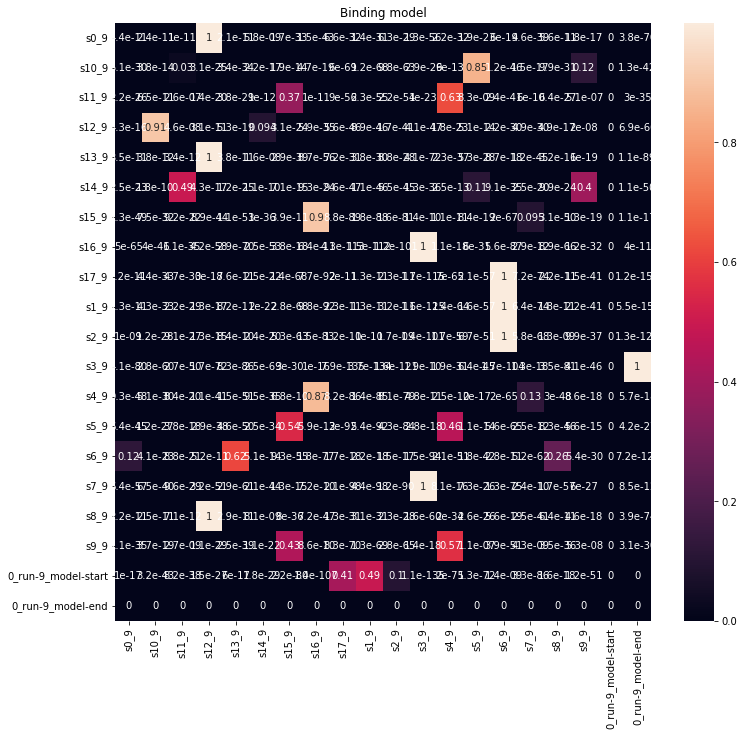

In [21]:
plt.figure(figsize=(12, 11))
ax = sns.heatmap(transition_b_df, annot=True)
ax.set_title("Binding model")

Text(0.5, 1.0, 'Immunogenicity model')

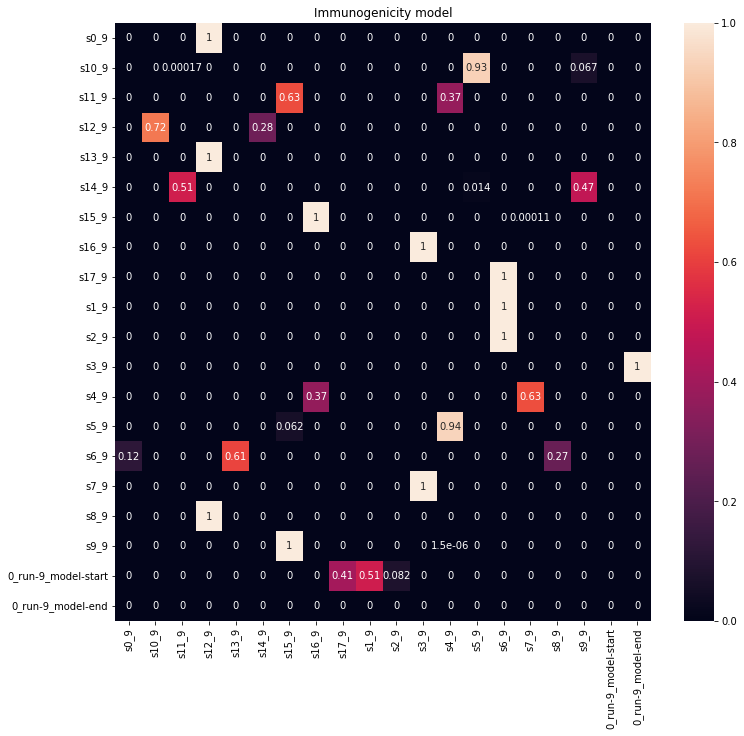

In [22]:
plt.figure(figsize=(12, 11))
ax = sns.heatmap(transition_i_df, annot=True)
ax.set_title("Immunogenicity model")

<AxesSubplot:>

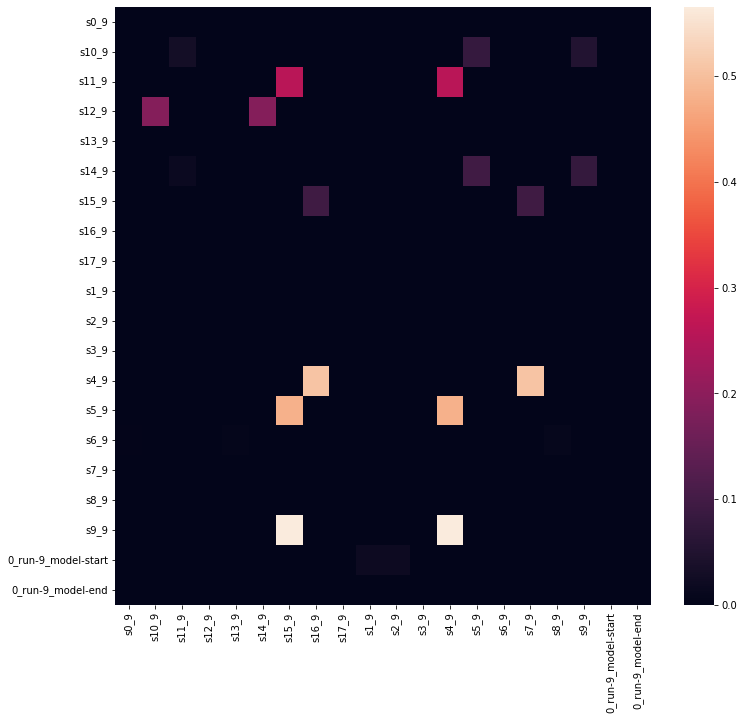

In [23]:
plt.figure(figsize=(12, 11))
sns.heatmap(diff_df)

<AxesSubplot:>

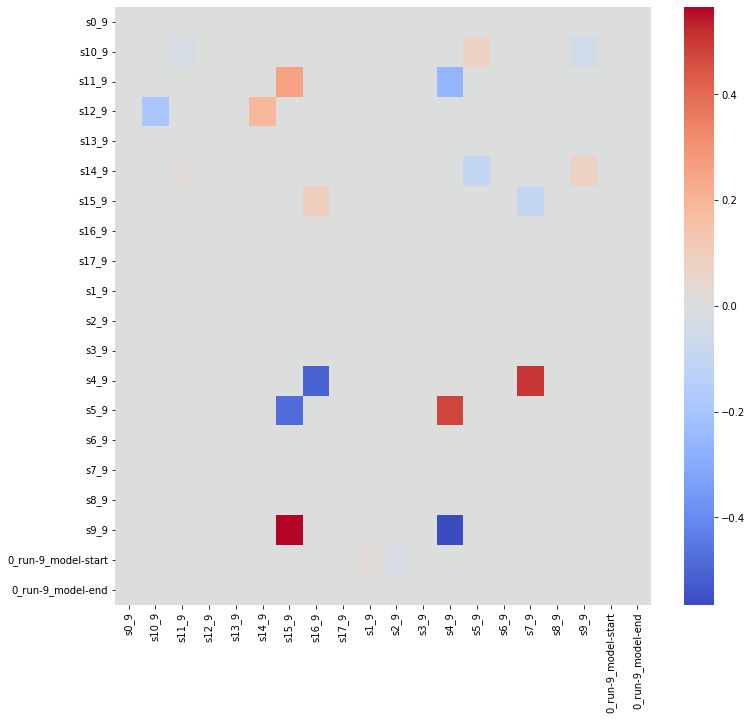

In [24]:
plt.figure(figsize=(12, 11))
sns.heatmap(diff2_df, cmap="coolwarm")

In [25]:
hottest_areas = np.ma.MaskedArray(diff2_df, np.abs(diff2_df) < 0)
X, Y = hottest_areas.nonzero()

hottest_points = [(x,y, value) for x, y , value in zip(X, Y, [hottest_areas[i,j] for i,j in zip(X,Y)])]
sorted_hottest_points = list(sorted(hottest_points, key=lambda x:np.abs(x[2]), reverse=True))
#print state_names
states_b = model_binding.states
name_to_change = defaultdict(int)
name_to_level = make_levels(model_binding)
transition_to_change = defaultdict(int)
for x,y, value in sorted_hottest_points:
    print(f"{states_b[x].name} -> {states_b[y].name} : {value}")
    name_to_change[states_b[x].name] += value
    # position is level - 2
    transition_to_change[f"{name_to_level[states_b[x].name] - 2}->{name_to_level[states_b[y].name] - 2}"] += np.abs(value)


s9_9 -> s15_9 : 0.5654207769493729
s9_9 -> s4_9 : -0.5654206074380346
s4_9 -> s7_9 : 0.5070118109332362
s4_9 -> s16_9 : -0.5070118099591276
s5_9 -> s4_9 : 0.48129201108018344
s5_9 -> s15_9 : -0.481292011071837
s11_9 -> s15_9 : 0.25686656892629006
s11_9 -> s4_9 : -0.2568657909541093
s12_9 -> s14_9 : 0.189820523247743
s12_9 -> s10_9 : -0.189820456668512
s14_9 -> s5_9 : -0.09678271017104831
s15_9 -> s16_9 : 0.09490155556295887
s15_9 -> s7_9 : -0.0949015553692331
s10_9 -> s5_9 : 0.08114956351574953
s14_9 -> s9_9 : 0.07918433897006227
s10_9 -> s9_9 : -0.05142749531517858
s10_9 -> s11_9 : -0.029722068199914336
0_run-9_model-start -> s1_9 : 0.018619195672179067
0_run-9_model-start -> s2_9 : -0.018048940691488533
s14_9 -> s11_9 : 0.017598371487392017
s6_9 -> s8_9 : 0.008334297837985005
s6_9 -> s13_9 : -0.004693422082693188
s6_9 -> s0_9 : -0.0036408756751309668
0_run-9_model-start -> s17_9 : -0.0005702535484405358
s11_9 -> s9_9 : -5.067676641679377e-07
s11_9 -> s11_9 : -2.62214907675531e-07
s9_

In [26]:
for position, value in sorted(transition_to_change.items()):
    print(position, value)

-1->0 0.037238389912108136
-1->1 1.4322499623722137e-09
-1->2 7.224182423032808e-17
-1->3 1.4932201824320755e-27
-1->4 1.8087525040765508e-29
-1->5 8.238233789694302e-38
-1->6 1.9939838096644773e-75
-1->7 3.2674894979768495e-86
-1->8 1.096939567768198e-135
0->0 2.0749656215117167e-09
0->1 5.451612494766778e-09
0->2 3.3766455295497317e-09
0->3 1.3350585728641864e-15
0->4 2.414078531680946e-20
0->5 9.170048244446552e-27
0->6 1.7144302950953426e-59
0->7 5.768357800959153e-68
0->8 1.3829241799408297e-101
0->9 1.3203346274503876e-122
1->0 1.9082519205631163e-17
1->1 2.827616063022519e-11
1->2 0.01666859559580916
1->3 5.183348498340026e-11
1->4 5.124714176443594e-14
1->5 8.751774275020071e-21
1->6 2.0536806697554523e-51
1->7 5.210583970865145e-62
1->8 1.4994132387685697e-94
1->9 7.188166601129564e-120
2->0 1.1745182203728169e-27
2->1 9.854754374347177e-18
2->2 3.3952948453759533e-10
2->3 3.082176525115443e-08
2->4 3.0461423131673055e-08
2->5 2.081256366186561e-11
2->6 2.4140796927711987e-32


## 4.2 Emissions

In [27]:
def get_emission_matrix(model):
    states_list = model.states
    emission_matrix = np.zeros(shape=(len(states_list), 20))
    for i,state in enumerate(states_list):
        if state.distribution is not None:
            amino_acids = list(state.distribution.parameters[0].keys())
            emission_matrix[i, :] = list(state.distribution.parameters[0].values())
    emissions_df = pd.DataFrame(emission_matrix, columns=amino_acids, index=[state.name for state in states_list])
    return emissions_df

def get_per_position_emission_df(model, emission_matrix_df):
    # We want to get per position pictures
    name_to_level = make_levels(model)
    per_position_rows = defaultdict(list)
    per_position_df = dict()
    for state_name in emission_matrix_df.index.values:
        position = name_to_level[state_name] - 2
        per_position_rows[position].append(emission_matrix_df.loc[state_name].copy())
    for position, rows in sorted(per_position_rows.items()):
        df = pd.DataFrame(rows)
        per_position_df[position] = df
    return per_position_df
    
    

    
    
emission_df_b = get_emission_matrix(model_binding)
    
emission_df_i = get_emission_matrix(model_immunogenic)


emission_df_b.head()


,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
s0_9,0.051012,0.015092,0.021809,0.145118,0.024600,0.008903,0.013198,0.095680,0.022034,0.231611,0.022125,0.044933,0.034268,0.066578,0.044893,0.011843,0.019674,0.086445,0.006233,0.033951
s10_9,0.061289,0.007674,0.043697,0.070734,0.054207,0.062692,0.042532,0.059197,0.073634,0.097427,0.013470,0.039217,0.040285,0.046411,0.048771,0.059319,0.063920,0.063980,0.011656,0.039889
s11_9,0.025986,0.008152,0.041825,0.105834,0.074352,0.052983,0.030228,0.065953,0.041214,0.053678,0.005337,0.063769,0.154837,0.094336,0.012579,0.112889,0.005589,0.015098,0.014729,0.020632
s12_9,0.065737,0.008104,0.124275,0.148669,0.018882,0.079682,0.025217,0.026739,0.057468,0.048295,0.008886,0.050969,0.083714,0.041919,0.032087,0.080012,0.045950,0.031305,0.006870,0.015221
s13_9,0.145135,0.000788,0.118617,0.001764,0.070745,0.041988,0.031249,0.046772,0.037271,0.131421,0.040403,0.034356,0.017974,0.040152,0.010431,0.093669,0.031105,0.046399,0.036329,0.023430


<AxesSubplot:>

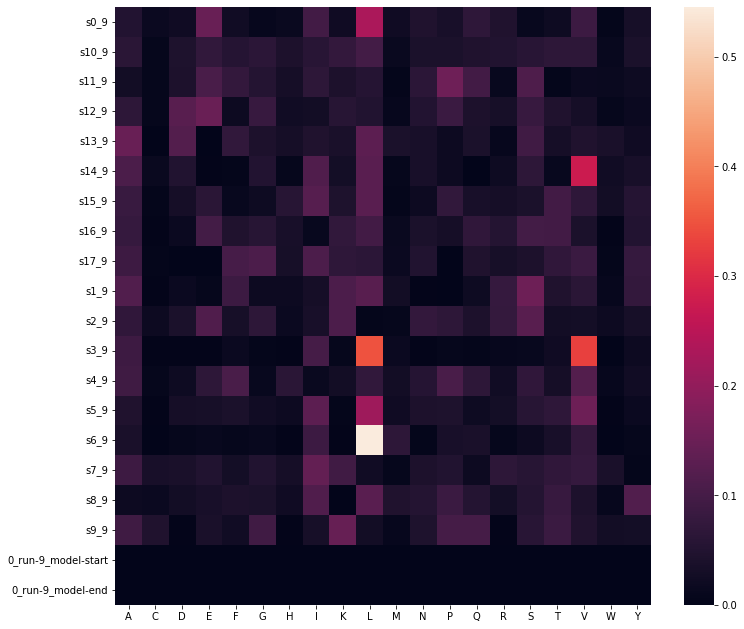

In [29]:
#heatmap
plt.figure(figsize=(12, 11))
sns.heatmap(emission_df_b)

<AxesSubplot:>

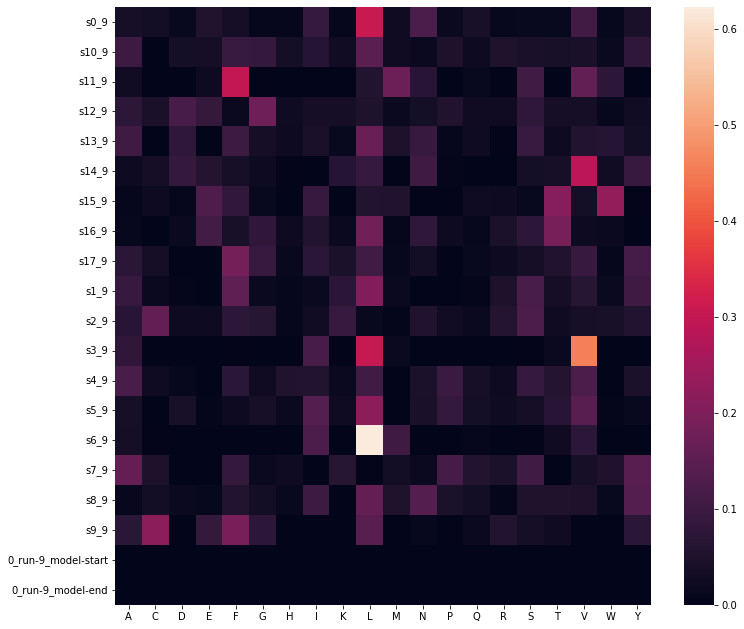

In [30]:
#heatmap
plt.figure(figsize=(12, 11))
sns.heatmap(emission_df_i)

In [31]:
per_position_emission_b_df = get_per_position_emission_df(model_binding, emission_df_b)

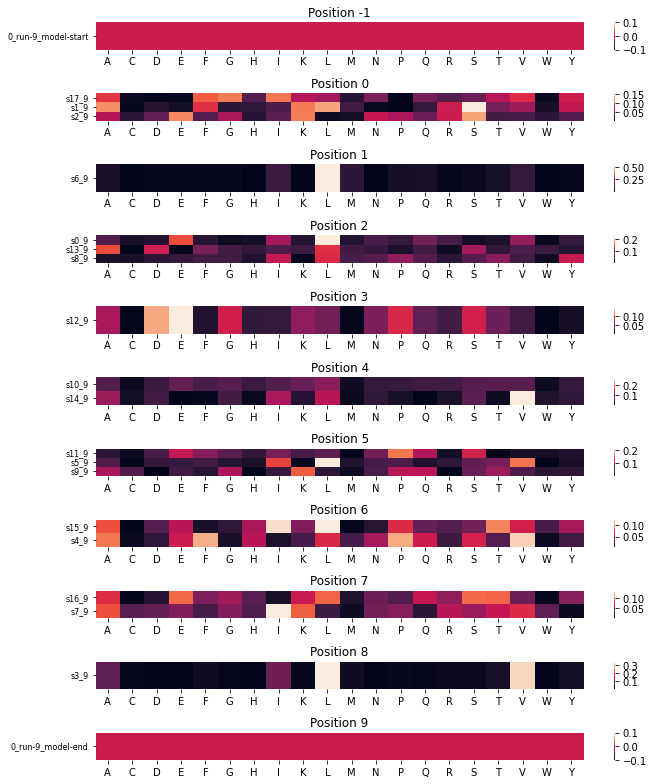

In [32]:
fig, axes = plt.subplots(nrows=len(per_position_emission_b_df), figsize=(10,11))
for i, (position, df) in enumerate(sorted(per_position_emission_b_df.items())):
    ax = axes[i]
    ax.set_title(f'Position {position}')
    g = sns.heatmap(df, ax=ax)
    g.set_yticklabels(g.get_yticklabels(), rotation = 0, fontsize = 8)
plt.tight_layout()


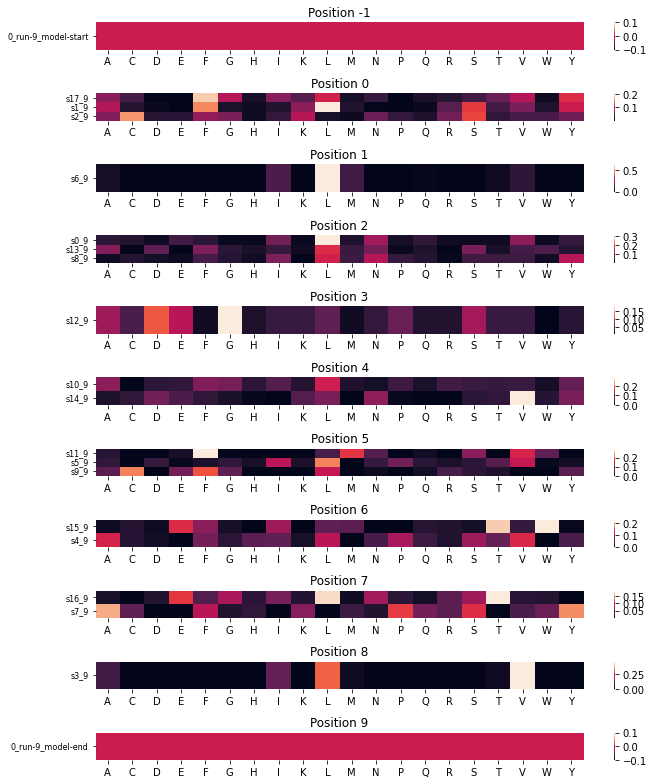

In [33]:
per_position_emission_i_df = get_per_position_emission_df(model_immunogenic, emission_df_i)
fig, axes = plt.subplots(nrows=len(per_position_emission_i_df), figsize=(10,11))
for i, (position, df) in enumerate(sorted(per_position_emission_i_df.items())):
    ax = axes[i]
    ax.set_title(f'Position {position}')
    g = sns.heatmap(df, ax=ax)
    g.set_yticklabels(g.get_yticklabels(), rotation = 0, fontsize = 8)
plt.tight_layout()


## Diference

<AxesSubplot:>

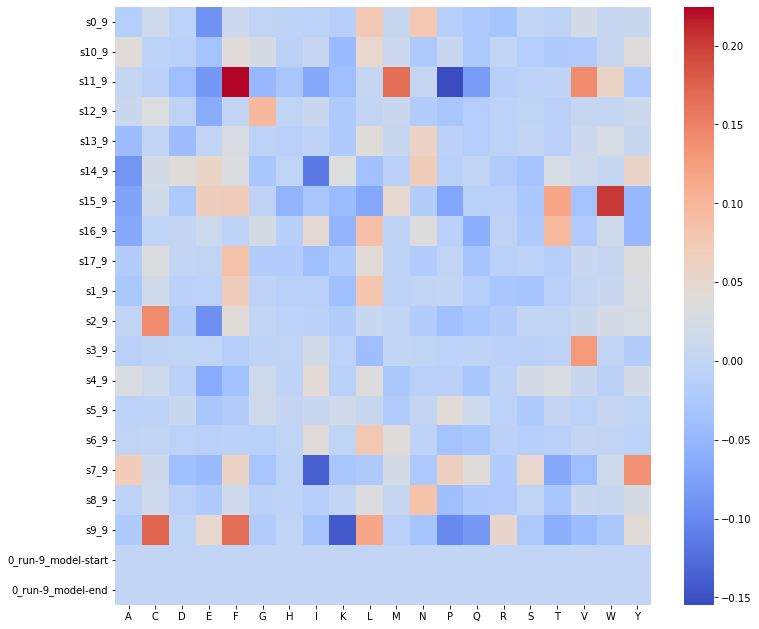

In [34]:
diff_df =  emission_df_i - emission_df_b
plt.figure(figsize=(12, 11))
sns.heatmap(diff_df, cmap="coolwarm")

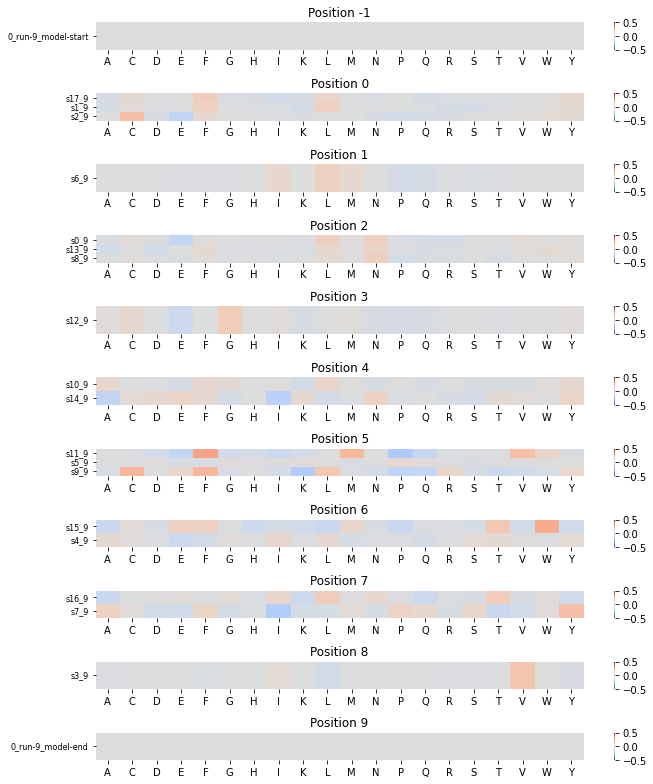

In [35]:
per_position_emission_diff_df = get_per_position_emission_df(model_binding, diff_df)
fig, axes = plt.subplots(nrows=len(per_position_emission_diff_df), figsize=(10,11))
for i, (position, df) in enumerate(sorted(per_position_emission_diff_df.items())):
    ax = axes[i]
    ax.set_title(f'Position {position}')
    g = sns.heatmap(df, ax=ax, cmap='coolwarm', vmin=-0.5, vmax=0.5)
    g.set_yticklabels(g.get_yticklabels(), rotation = 0, fontsize = 8)
plt.tight_layout()

In [36]:
per_position_emission_b_df[2].sum().values.reshape(1,-1)

array([[0.21401981, 0.03185278, 0.16797465, 0.18175365, 0.13699359,
        0.09061655, 0.06576848, 0.25537466, 0.06004768, 0.49058972,
        0.10768743, 0.13215111, 0.13699485, 0.15861049, 0.08309439,
        0.15791338, 0.13056862, 0.17405047, 0.05151519, 0.17242249]])

In [37]:
df = pd.DataFrame(per_position_emission_b_df[2].sum().values.reshape(1,-1), columns = per_position_emission_b_df[2].columns )

In [38]:
per_position_emission_b_df[2]

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
s0_9,0.051012,0.015092,0.021809,0.145118,0.024600,0.008903,0.013198,0.095680,0.022034,0.231611,0.022125,0.044933,0.034268,0.066578,0.044893,0.011843,0.019674,0.086445,0.006233,0.033951
s13_9,0.145135,0.000788,0.118617,0.001764,0.070745,0.041988,0.031249,0.046772,0.037271,0.131421,0.040403,0.034356,0.017974,0.040152,0.010431,0.093669,0.031105,0.046399,0.036329,0.023430
s8_9,0.017872,0.015973,0.027548,0.034872,0.041649,0.039725,0.021321,0.112922,0.000743,0.127558,0.045159,0.052862,0.084752,0.051881,0.027770,0.052401,0.079790,0.041206,0.008953,0.115041


In [39]:
df

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
0,0.21402,0.031853,0.167975,0.181754,0.136994,0.090617,0.065768,0.255375,0.060048,0.49059,0.107687,0.132151,0.136995,0.15861,0.083094,0.157913,0.130569,0.17405,0.051515,0.172422


In [47]:
def get_path_changes(df_b, df_i, paths_df):
    path_index_to_score_db = defaultdict(int)
    for index, row in df_b.iterrows():
        for path_index, column_value in enumerate(row):
            path_index_to_score_db[path_index] += column_value
            # if column_value > treshold:
            #     path_index_to_score_db[path_index] += 1

    path_index_to_score_di = defaultdict(int)
    for index, row in df_i.iterrows():
        for path_index, column_value in enumerate(row):
            path_index_to_score_di[path_index] += column_value
            # if column_value > treshold:
            #     path_index_to_score_di[path_index] += 1
                
    #normalize by size of sample

    for path_index in path_index_to_score_db:
        path_index_to_score_db[path_index] = path_index_to_score_db[path_index] / len(df_b)


    for path_index in path_index_to_score_di:
        path_index_to_score_di[path_index] = path_index_to_score_di[path_index] / len(df_i)
    dfb = pd.DataFrame.from_dict(path_index_to_score_db, orient='index', columns=["value"])
    dfi = pd.DataFrame.from_dict(path_index_to_score_di, orient='index', columns=["value"])
    merge_df = pd.merge(dfb, dfi, left_index=True, right_index=True, suffixes=['_b','_i'])
    merge_df['diff'] = merge_df['value_i'].subtract(merge_df['value_b'], fill_value=0)
    
    paths_df_copy = paths_df.copy()
    paths_df_copy[['start'] +  [f'state_{i}' for i in range(target_length)] + ['end'] ] = pd.DataFrame(paths_df_copy['path'].to_list(), index=paths_df_copy.index)
    paths_df_copy= paths_df_copy.drop(columns=['start', 'end', 'path'])
    

    total_df = pd.merge(merge_df, paths_df_copy,  left_index=True, right_index=True, suffixes=['_b','_i'])
    return total_df

<AxesSubplot:>

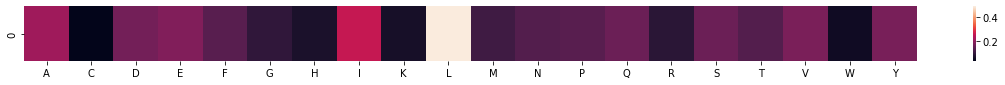

In [40]:
plt.figure(figsize=(20,1))
sns.heatmap(df)

In [41]:
import scipy
positions = list()
states = list()
state_entropies = list()
position_entropies = list()

for i, (position, df) in enumerate(sorted(per_position_emission_b_df.items())):
    df_b = df
    df_i = per_position_emission_i_df[position]

    sum_row_b = df_b.sum()
    sum_row_i = df_i.sum()
    sum_entropy =  scipy.stats.entropy(sum_row_i.values, sum_row_b.values)
    print(f"Position {position}")
    print(f"Position entropy: {np.round(sum_entropy,3)}")
    for (name_b, row_b), (name_i, row_i) in zip(df_b.iterrows(),df_i.iterrows()):
        assert name_b == name_i
        entropy = scipy.stats.entropy(row_i.values, row_b.values)
        if entropy ==  np.inf:
            print(f" b : {row_b.values}")
            print(f" i : {row_i.values}")
        print(f"{name_b} change -> {np.round(entropy,3)}")
        positions.append(position)
        states.append(name_b)
        state_entropies.append(np.round(entropy,3))
        position_entropies.append(np.round(sum_entropy,3))


result = pd.DataFrame({"position": positions, "state": states, "state entropy": state_entropies, "position entropy": position_entropies})


Position -1
Position entropy: nan
0_run-9_model-start change -> nan
Position 0
Position entropy: 0.199
s17_9 change -> 0.142
s1_9 change -> 0.119
s2_9 change -> 0.348
Position 1
Position entropy: 0.152
s6_9 change -> 0.152
Position 2
Position entropy: 0.117
s0_9 change -> 0.146
s13_9 change -> 0.094
s8_9 change -> 0.113
Position 3
Position entropy: 0.126
s12_9 change -> 0.126
Position 4
Position entropy: 0.089
s10_9 change -> 0.125
s14_9 change -> 0.517
Position 5
Position entropy: 0.337
s11_9 change -> 1.43
s5_9 change -> 0.093
s9_9 change -> 1.124
Position 6
Position entropy: 0.228
s15_9 change -> 0.89
s4_9 change -> 0.211
Position 7
Position entropy: 0.112
s16_9 change -> 0.324
s7_9 change -> 0.814
Position 8
Position entropy: 0.112
s3_9 change -> 0.112
Position 9
Position entropy: nan
0_run-9_model-end change -> nan


d:\tools\python\anaconda\envs\pomegranate-env\lib\site-packages\scipy\stats\_entropy.py:72: RuntimeWarning: invalid value encountered in true_divide
  pk = 1.0*pk / np.sum(pk, axis=axis, keepdims=True)
d:\tools\python\anaconda\envs\pomegranate-env\lib\site-packages\scipy\stats\_entropy.py:78: RuntimeWarning: invalid value encountered in true_divide
  qk = 1.0*qk / np.sum(qk, axis=axis, keepdims=True)


In [42]:
result

,position,state,state entropy,position entropy
0,-1,0_run-9_model-start,NaN,NaN
1,0,s17_9,0.142,0.199
2,0,s1_9,0.119,0.199
3,0,s2_9,0.348,0.199
4,1,s6_9,0.152,0.152
5,2,s0_9,0.146,0.117
6,2,s13_9,0.094,0.117
7,2,s8_9,0.113,0.117
8,3,s12_9,0.126,0.126
9,4,s10_9,0.125,0.089


In [43]:
result[['position', 'position entropy']].drop_duplicates()

,position,position entropy
0,-1,NaN
1,0,0.199
4,1,0.152
5,2,0.117
8,3,0.126
9,4,0.089
11,5,0.337
14,6,0.228
16,7,0.112
18,8,0.112


In [44]:
result[['position','state' ,'state entropy']]

,position,state,state entropy
0,-1,0_run-9_model-start,NaN
1,0,s17_9,0.142
2,0,s1_9,0.119
3,0,s2_9,0.348
4,1,s6_9,0.152
5,2,s0_9,0.146
6,2,s13_9,0.094
7,2,s8_9,0.113
8,3,s12_9,0.126
9,4,s10_9,0.125


In [45]:
# We want to get per position pictures
name_to_level = make_levels(model_binding)

per_position_rows = defaultdict(list)
for state_name in diff_df.index.values:

    position = name_to_level[state_name] - 2
    per_position_rows[position].append(diff_df.loc[state_name].copy())

# Evaluare paths

## Model binding
### Generated_data

In [140]:
generated_df_repr_db = pivot_data_dict['Generated']['db']['mb']
generated_df_repr_di = pivot_data_dict['Generated']['di']['mb']

In [48]:
total_df = get_path_changes(generated_df_repr_db, generated_df_repr_di, df_b_paths).sort_values('diff')
total_df.to_csv("generated_paths_changes.csv")

In [49]:
total_df

,value_b,value_i,diff,prob,state_0,state_1,state_2,state_3,state_4,state_5,state_6,state_7,state_8
174,-27.821970,-27.830812,-0.008842,-7.652231,s17_9,s6_9,s8_9,s12_9,s10_9,s9_9,s15_9,s7_9,s3_9
150,-29.690698,-29.671167,0.019531,-8.410397,s17_9,s6_9,s0_9,s12_9,s10_9,s9_9,s15_9,s7_9,s3_9
178,-30.096072,-30.047793,0.048279,-9.185800,s17_9,s6_9,s8_9,s12_9,s10_9,s11_9,s15_9,s7_9,s3_9
172,-27.595814,-27.531450,0.064364,-7.110127,s17_9,s6_9,s8_9,s12_9,s10_9,s9_9,s4_9,s7_9,s3_9
154,-31.964799,-31.888148,0.076652,-9.943967,s17_9,s6_9,s0_9,s12_9,s10_9,s11_9,s15_9,s7_9,s3_9
...,...,...,...,...,...,...,...,...,...,...,...,...,...
63,-32.986259,-32.136532,0.849727,-6.470943,s1_9,s6_9,s13_9,s12_9,s14_9,s5_9,s15_9,s16_9,s3_9
141,-33.661834,-32.789957,0.871877,-6.451250,s2_9,s6_9,s13_9,s12_9,s14_9,s11_9,s4_9,s16_9,s3_9
69,-33.847241,-32.974183,0.873059,-4.861217,s1_9,s6_9,s13_9,s12_9,s14_9,s11_9,s4_9,s16_9,s3_9
133,-33.586268,-32.664517,0.921750,-8.269604,s2_9,s6_9,s13_9,s12_9,s14_9,s5_9,s4_9,s16_9,s3_9


### Train data

In [50]:
train_df_repr_db = pivot_data_dict['Train']['db']['mb']
train_df_repr_di = pivot_data_dict['Train']['di']['mb']

In [51]:
total_df = get_path_changes(train_df_repr_db, train_df_repr_di, df_b_paths).sort_values('diff')
total_df.to_csv("train_paths_changes.csv")

In [52]:
total_df.sort_values('diff')

,value_b,value_i,diff,prob,state_0,state_1,state_2,state_3,state_4,state_5,state_6,state_7,state_8
174,-27.759870,-27.825757,-0.065887,-7.652231,s17_9,s6_9,s8_9,s12_9,s10_9,s9_9,s15_9,s7_9,s3_9
150,-29.608715,-29.671476,-0.062761,-8.410397,s17_9,s6_9,s0_9,s12_9,s10_9,s9_9,s15_9,s7_9,s3_9
178,-30.016460,-30.046735,-0.030275,-9.185800,s17_9,s6_9,s8_9,s12_9,s10_9,s11_9,s15_9,s7_9,s3_9
154,-31.865306,-31.892454,-0.027148,-9.943967,s17_9,s6_9,s0_9,s12_9,s10_9,s11_9,s15_9,s7_9,s3_9
172,-27.523992,-27.540213,-0.016221,-7.110127,s17_9,s6_9,s8_9,s12_9,s10_9,s9_9,s4_9,s7_9,s3_9
...,...,...,...,...,...,...,...,...,...,...,...,...,...
135,-32.682150,-31.927068,0.755082,-8.060976,s2_9,s6_9,s13_9,s12_9,s14_9,s5_9,s15_9,s16_9,s3_9
69,-33.757965,-32.982866,0.775098,-4.861217,s1_9,s6_9,s13_9,s12_9,s14_9,s11_9,s4_9,s16_9,s3_9
141,-33.550860,-32.764498,0.786362,-6.451250,s2_9,s6_9,s13_9,s12_9,s14_9,s11_9,s4_9,s16_9,s3_9
61,-33.664951,-32.871466,0.793485,-6.679571,s1_9,s6_9,s13_9,s12_9,s14_9,s5_9,s4_9,s16_9,s3_9


## Model Immunogenic
### Generated data

In [53]:
generated_df_repr_db = pivot_data_dict['Generated']['db']['mi']
generated_df_repr_di = pivot_data_dict['Generated']['di']['mi']

In [54]:
total_df = get_path_changes(generated_df_repr_db, generated_df_repr_di, df_i_paths).sort_values('diff')
total_df.to_csv("generated_paths_changes_mi.csv")

In [55]:
df_i_paths['path'].values

array([list(['0_run-9_model-start', 's1_9', 's6_9', 's13_9', 's12_9', 's10_9', 's5_9', 's4_9', 's7_9', 's3_9', '0_run-9_model-end']),
       list(['0_run-9_model-start', 's17_9', 's6_9', 's13_9', 's12_9', 's10_9', 's5_9', 's4_9', 's7_9', 's3_9', '0_run-9_model-end']),
       list(['0_run-9_model-start', 's1_9', 's6_9', 's13_9', 's12_9', 's10_9', 's5_9', 's4_9', 's16_9', 's3_9', '0_run-9_model-end']),
       list(['0_run-9_model-start', 's17_9', 's6_9', 's13_9', 's12_9', 's10_9', 's5_9', 's4_9', 's16_9', 's3_9', '0_run-9_model-end']),
       list(['0_run-9_model-start', 's1_9', 's6_9', 's8_9', 's12_9', 's10_9', 's5_9', 's4_9', 's7_9', 's3_9', '0_run-9_model-end']),
       list(['0_run-9_model-start', 's17_9', 's6_9', 's8_9', 's12_9', 's10_9', 's5_9', 's4_9', 's7_9', 's3_9', '0_run-9_model-end']),
       list(['0_run-9_model-start', 's1_9', 's6_9', 's13_9', 's12_9', 's14_9', 's9_9', 's15_9', 's16_9', 's3_9', '0_run-9_model-end']),
       list(['0_run-9_model-start', 's17_9', 's6_9', 's13

### Train data

In [56]:
train_df_repr_db = pivot_data_dict['Train']['db']['mi']
train_df_repr_di = pivot_data_dict['Train']['di']['mi']

In [57]:
total_df = get_path_changes(train_df_repr_db, train_df_repr_di, df_i_paths).sort_values('diff')
total_df.to_csv("train_paths_changes_mi.csv")

In [58]:
total_df.head()

,value_b,value_i,diff,prob,state_0,state_1,state_2,state_3,state_4,state_5,state_6,state_7,state_8
122,-7867.789120,-47.795748,7819.993373,-15.365999,s17_9,s6_9,s0_9,s12_9,s10_9,s5_9,s15_9,s7_9,s3_9
123,-7868.367687,-48.366328,7820.001359,-6.205285,s17_9,s6_9,s0_9,s12_9,s10_9,s5_9,s15_9,s16_9,s3_9
162,-7867.092587,-46.899702,7820.192886,-13.725153,s17_9,s6_9,s13_9,s12_9,s10_9,s5_9,s15_9,s7_9,s3_9
163,-7867.671154,-47.470282,7820.200872,-4.564439,s17_9,s6_9,s13_9,s12_9,s10_9,s5_9,s15_9,s16_9,s3_9
142,-7866.202531,-45.950029,7820.252502,-14.546166,s17_9,s6_9,s8_9,s12_9,s10_9,s5_9,s15_9,s7_9,s3_9


In [59]:
train_df_repr_di

path_index,0,1,2,3,4,5,6,7,8,9,...,170,171,172,173,174,175,176,177,178,179
peptide,,,,,,,,,,,,,,,,,,,,,
AIMDKNIML,-37.705460,-45.580093,-39.711705,-37.882320,-31.823253,-39.697886,-30.588782,-28.759398,-33.014053,-40.888685,...,-29.953692,-37.828325,-31.959937,-30.130552,-36.341958,-44.216591,-35.107487,-33.278103,-31.344572,-39.219204
AIYDTMQYV,-40.103355,-43.094483,-41.181341,-34.468452,-45.988859,-48.979987,-43.826129,-37.113240,-39.759050,-42.750178,...,-32.775551,-35.766679,-33.853537,-27.140648,-50.931528,-53.922656,-48.768798,-42.055909,-38.513533,-41.504661
ALDEGLLPV,-35.180080,-42.661182,-36.094230,-33.871315,-27.495109,-34.976211,-25.168543,-22.945628,-27.774828,-35.255931,...,-30.206197,-37.687299,-31.120347,-28.897432,-34.791698,-42.272801,-32.465133,-30.242218,-28.883232,-36.364335
ALGGGATGV,-33.136519,-43.800561,-35.924218,-36.884242,-26.529817,-37.193859,-26.076800,-27.036824,-25.817144,-36.481186,...,-26.900588,-37.564630,-29.688286,-30.648311,-32.564359,-43.228401,-32.111341,-33.071366,-25.663499,-36.327542
ALIHHNTYL,-38.821291,-41.812419,-41.608989,-34.896100,-32.939084,-35.930212,-32.486067,-25.773178,-34.129884,-37.121012,...,-34.378515,-37.369644,-37.166214,-30.453325,-40.766781,-43.757910,-40.313764,-33.600875,-35.769395,-38.760523
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YTMDGEYRL,-40.204059,-49.389344,-39.439505,-38.920773,-35.114696,-44.299981,-31.109426,-30.590694,-32.233572,-41.418857,...,-35.378456,-44.563741,-34.613902,-34.095170,-42.559565,-51.744851,-38.554296,-38.035564,-33.490255,-42.675540
YVDDVVLGA,-36.616551,-47.280593,-37.530701,-38.490726,-30.376065,-41.040108,-28.049500,-29.009525,-35.904389,-46.568432,...,-28.893658,-39.557700,-29.807808,-30.767833,-34.923645,-45.587688,-32.597080,-33.557105,-34.263784,-44.927826
YVLDHLIVV,-33.968129,-42.501977,-35.974373,-34.804205,-26.283158,-34.817007,-25.048687,-23.878518,-26.562877,-35.096726,...,-30.915694,-39.449543,-32.921939,-31.751771,-35.501196,-44.035045,-34.266725,-33.096557,-29.592730,-38.126579


## Some statistics test with known answer

In [58]:
df = pd.read_csv('D:\\Sandbox\onesnp.csv', header=None, names=['acid', 'value'])
df.head()

,acid,value
0,C,1
1,G,0
2,G,0
3,T,1
4,G,0


In [59]:
from scipy.stats import chi2

def get_sz(a, b):
    return len(df[(df.acid.astype('str') == a) & (df["value"] == b)])

def xi(a, b):
    m1 = 0
    for i in ["A", "C", "G", "T"]:
        m1 += get_sz(i, b)
    m2 = get_sz(a, 0) + get_sz(a, 1)

    n = len(df)
    return (((get_sz(a, b) - m1 * m2 / n) ** 2) / (m1 * m2 / n))

def glob_xi():
    res = 0
    for i in [0, 1]:
        for j in ["A", "C", "G", "T"]:
            res += xi(j, i)
    return res

print("A:", get_sz('A', 1), get_sz('A', 0))
print("C:", get_sz('C', 1), get_sz('C', 0))
print("G:", get_sz('G', 1), get_sz('G', 0))
print("T:", get_sz('T', 1), get_sz('T', 0))

print("chi^2:", glob_xi())
print("p-value:", 1 - chi2.cdf(glob_xi(), 3))

A: 1199 1224
C: 1266 1259
G: 1253 1286
T: 1276 1237
chi^2: 1.2971142104271318
p-value: 0.7298184494688893


In [60]:
crosstab = pd.crosstab( df['value'],df['acid'])
crosstab

acid,A,C,G,T
value,,,,
0,1224,1259,1286,1237
1,1199,1266,1253,1276


## with statsmodels

In [61]:
import statsmodels.api as sm
table = sm.stats.Table(crosstab)

In [62]:
rslt = table.test_nominal_association()
print("p-value" , rslt.pvalue)
table.chi2_contribs

p-value 0.7298184494688896


acid,A,C,G,T
value,,,,
0,0.100596,0.019897,0.176471,0.350815
1,0.100838,0.019945,0.176895,0.351658


## with sklearn

In [63]:
from sklearn.feature_selection import chi2
from scipy.stats import chi2_contingency

In [64]:
stat, p, dof, expected = chi2_contingency(crosstab)
stat, p, dof, expected

(1.2971142104271318,
 0.7298184494688893,
 3,
 array([[1212.9538, 1264.015 , 1271.0234, 1258.0078],
        [1210.0462, 1260.985 , 1267.9766, 1254.9922]]))

## For binders

In [65]:
binders = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][split_num][target_length]
non_binders = per_allele_per_kfold_per_length_non_binders_train[ALLELES[0]][split_num][target_length]

In [66]:
non_binders_df = pd.DataFrame([list(peptide) for peptide in non_binders])
non_binders_df['binder'] = 0
binders_df = pd.DataFrame([list(peptide) for peptide in binders])
binders_df['binder'] = 1


In [67]:
total_df = pd.concat([binders_df, non_binders_df])

In [68]:
total_df

,0,1,2,3,4,5,6,7,8,binder
0,T,L,Q,S,K,D,F,K,L,1
1,L,L,L,E,V,S,E,E,L,1
2,V,V,V,K,I,L,K,P,V,1
3,A,V,M,Q,E,V,P,L,A,1
4,A,V,N,A,A,V,Q,R,V,1
...,...,...,...,...,...,...,...,...,...,...
5682,W,E,Y,W,G,A,Q,L,N,0
5683,R,T,R,G,P,L,G,I,L,0
5684,R,A,R,I,K,T,R,L,F,0
5685,K,L,D,F,I,R,N,T,K,0


In [69]:
amino_acids = list('ACDEFGHIKLMNPQRSTVWY')

In [70]:
from scipy.stats import chi2_contingency
crosstab = pd.crosstab(total_df['binder'],  total_df[2])
rslt_scipy = chi2_contingency(crosstab)
b = sm.stats.Table(crosstab).test_nominal_association()
b.pvalue


0.0

In [71]:
p_values = list()
p_values_scipy = list()
chi2_contribs = list()
for position in range(target_length):
    print(f"position {position}")
    crosstab = pd.crosstab(total_df[position], total_df['binder'])
    table = sm.stats.Table(crosstab)
    rslt = table.test_nominal_association()
    print("p-value nominal" , rslt.pvalue)
    p_values.append(rslt.pvalue)
    stat, p, dof, expected = chi2_contingency(crosstab)
    p_values_scipy.append(p)
    # rslt = table.test_ordinal_association()
    # print("p-value ordinal" , rslt.pvalue)
    # print(table.chi2_contribs)
    chi2_contribs.append(table.chi2_contribs)
    
          

position 0
p-value nominal 0.0
position 1
p-value nominal 0.0
position 2
p-value nominal 0.0
position 3
p-value nominal 0.0
position 4
p-value nominal 0.0
position 5
p-value nominal 0.0
position 6
p-value nominal 0.0
position 7
p-value nominal 0.0
position 8
p-value nominal 0.0


In [72]:
crosstab

binder,0,1
8,,
A,390,2167
C,50,102
D,73,59
E,106,101
F,425,407
G,122,115
H,71,59
I,535,2344
K,365,193


In [73]:
from statsmodels.stats.multitest import multipletests
rejects, p_values, significance1, significance2 = multipletests(pvals=p_values_scipy, alpha=0.05, method='holm')


In [74]:
pd.DataFrame({"position":[i for i in range(target_length)],"p-value":p_values, "reject H0": rejects})

,position,p-value,reject H0
0,0,0.000000e+00,True
1,1,0.000000e+00,True
2,2,4.616229e-176,True
3,3,7.679573e-230,True
4,4,3.302684e-40,True
5,5,1.741724e-251,True
6,6,6.438037e-192,True
7,7,4.251359e-161,True
8,8,0.000000e+00,True


## For immune peptides

In [75]:
imm = per_allele_per_kfold_per_length_immunogenic_train[ALLELES[0]][split_num][target_length]
non_imm = per_allele_per_kfold_per_length_non_immunogenic_train[ALLELES[0]][split_num][target_length]

In [76]:
non_imm_df = pd.DataFrame([list(peptide) for peptide in non_imm])
non_imm_df['imm'] = 0
imm_df = pd.DataFrame([list(peptide) for peptide in imm])
imm_df['imm'] = 1


In [77]:
total_df = pd.concat([imm_df, non_imm_df])

In [78]:
total_df

,0,1,2,3,4,5,6,7,8,imm
0,T,L,W,C,S,P,I,K,V,1
1,N,M,F,T,P,Y,I,G,V,1
2,L,L,L,G,L,M,I,L,L,1
3,F,T,L,V,A,P,V,S,I,1
4,K,L,S,E,G,D,L,L,A,1
...,...,...,...,...,...,...,...,...,...,...
347,I,L,F,L,F,F,C,F,V,0
348,W,L,I,T,F,V,L,N,A,0
349,F,L,P,A,Y,L,N,S,L,0
350,V,L,L,A,L,V,L,L,L,0


In [79]:
p_values = list()
p_values_scipy = list()
chi2_contribs = list()
for position in range( target_length):
    print(f"position {position}")
    df_copy = total_df.copy()[[position, "imm"]]
    crosstab = pd.crosstab(df_copy[position], df_copy['imm'])
    table = sm.stats.Table(crosstab)
    rslt = table.test_nominal_association()
    print("p-value nominal" , rslt.pvalue)
    rslt = table.test_ordinal_association()
    print("p-value ordinal" , rslt.pvalue)
    stat, p, dof, expected = chi2_contingency(crosstab)
    p_values_scipy.append(p)
    chi2_contribs.append(table.chi2_contribs)
    

position 0
p-value nominal 0.3006046229771133
p-value ordinal 0.8795366720276284
position 1
p-value nominal 0.005804262731529453
p-value ordinal 0.43222726625311514
position 2
p-value nominal 0.06230208219212463
p-value ordinal 0.044195758793265004
position 3
p-value nominal 9.90934518818598e-06
p-value ordinal 0.015844692907315487
position 4
p-value nominal 0.08393153398839426
p-value ordinal 0.10288481825528822
position 5
p-value nominal 0.22776502185138114
p-value ordinal 0.012735044754480855
position 6
p-value nominal 0.002768752543128361
p-value ordinal 0.0004157001000506472
position 7
p-value nominal 0.013633049686710308
p-value ordinal 0.041002406326065166
position 8
p-value nominal 0.00128909000149946
p-value ordinal 0.002057482794788115


In [80]:
from statsmodels.stats.multitest import multipletests
rejects, p_values, significance1, significance2 = multipletests(pvals=p_values_scipy, alpha=0.05, method='holm')


In [81]:
pd.DataFrame({"position":[i for i in range(target_length)],"p-value":p_values, "reject H0": rejects})

,position,p-value,reject H0
0,0,0.455530,False
1,1,0.001116,True
2,2,0.249208,False
3,3,0.000079,True
4,4,0.251795,False
5,5,0.455530,False
6,6,0.016613,True
7,7,0.068165,False
8,8,0.000054,True


In [82]:
from statsmodels.stats.multitest import multipletests
multipletests(pvals=p_values_scipy, alpha=0.05, method='holm')


(array([False,  True, False,  True, False, False,  True, False,  True]),
 array([4.55530044e-01, 1.11620141e-03, 2.49208329e-01, 7.92747615e-05,
        2.51794602e-01, 4.55530044e-01, 1.66125153e-02, 6.81652484e-02,
        5.44742406e-05]),
 0.005683044988048058,
 0.005555555555555556)

In [83]:
chi2_contribs[7]

imm,0,1
7,,
A,0.108632,0.095835
C,0.033425,0.029488
D,0.004708,0.004153
E,0.129522,0.114265
F,0.928890,0.819472
G,0.031900,0.028142
H,0.048119,0.042451
I,0.092062,0.081218
K,0.269897,0.238105


In [84]:
total_df

,0,1,2,3,4,5,6,7,8,imm
0,T,L,W,C,S,P,I,K,V,1
1,N,M,F,T,P,Y,I,G,V,1
2,L,L,L,G,L,M,I,L,L,1
3,F,T,L,V,A,P,V,S,I,1
4,K,L,S,E,G,D,L,L,A,1
...,...,...,...,...,...,...,...,...,...,...
347,I,L,F,L,F,F,C,F,V,0
348,W,L,I,T,F,V,L,N,A,0
349,F,L,P,A,Y,L,N,S,L,0
350,V,L,L,A,L,V,L,L,L,0


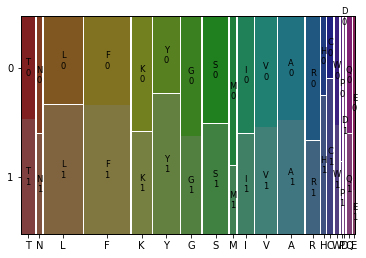

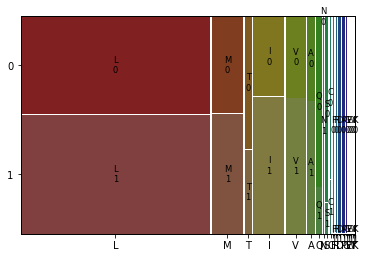

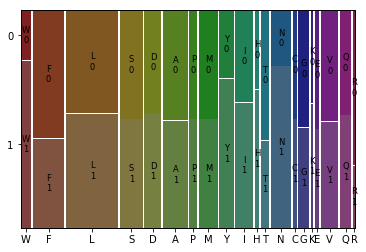

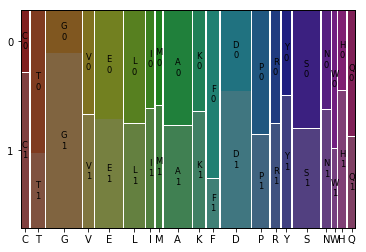

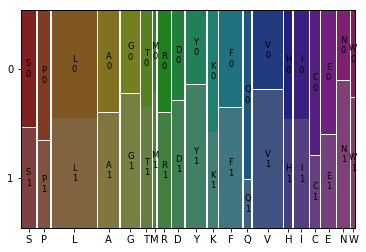

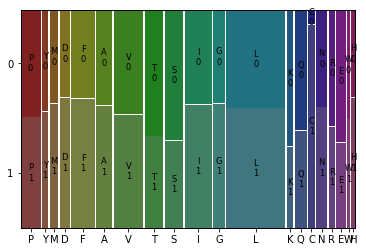

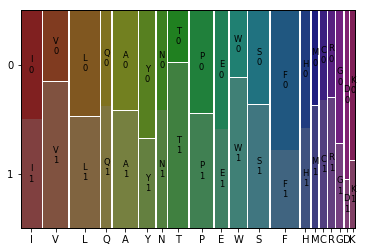

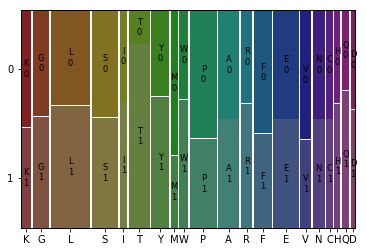

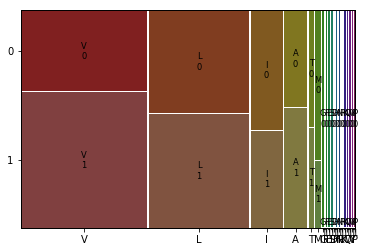

In [85]:
from statsmodels.graphics.mosaicplot import mosaic
for position in range(0,target_length):
    fig, _ = mosaic(total_df, index=[position, "imm"])

# Motifs for top paths

In [60]:
from mhcgnomes import parse
# decoy data
def defineOrganism(allele_name):
    parse_result = parse(allele_name)
    if parse_result.is_mouse:
        return "Mouse"
    elif parse_result.is_human:
        return "Human"
    else:
        print("organism not found")
        return None


def defineClass(allele_name):
    parse_result = parse(allele_name)
    if parse_result.has_mhc_class:
        if parse_result.is_class1:
            return 'I'
        elif parse_result.is_class2:
            return 'II'
        else:
            print("Not class I or class II???!")
    else:
        print("Result without class")
    return None

per_allele_decoy = dict()
for allele_name in ALLELES:
    organism =  defineOrganism(allele_name).lower()
    class_to_use = defineClass(allele_name)
    DECOY_DATA_PATH = f"D:\Google Drive\Work\ITMO\data\decoy\sampled_decoy_data_{organism}_class_{class_to_use}.csv"
    decoy_df =  pd.read_csv(DECOY_DATA_PATH)
    decoy_df['length'] = decoy_df['peptide'].str.len()
    
    per_allele_decoy[allele_name] = decoy_df.copy()[decoy_df['length'] == target_length]

In [61]:
decoy_data = per_allele_decoy[ALLELES[0]]
len(decoy_data)

401984

In [62]:
decoy_data['b_score'] = [model_binding.log_probability(peptide) for peptide in decoy_data['peptide'].values]
decoy_data['i_score'] = [model_immunogenic.log_probability(peptide) for peptide in decoy_data['peptide'].values]
decoy_data['diff_score'] =  decoy_data['i_score'] - decoy_data['b_score']

In [63]:
decoy_data

,peptide,length,b_score,i_score,diff_score
10,QYPSESSVL,9,-26.766927,-inf,-inf
14,EQSHRPFLM,9,-29.027224,-32.446512,-3.419287
17,MIRNILLMH,9,-30.297066,-inf,-inf
22,PGTASAAHR,9,-31.602074,-inf,-inf
24,KMFTPPSES,9,-26.968568,-28.462313,-1.493745
...,...,...,...,...,...
1999983,ITGTKEGIE,9,-31.897570,-inf,-inf
1999986,KAKRAVQRG,9,-28.959812,-inf,-inf
1999993,SPLGPWLSS,9,-27.673548,-inf,-inf
1999995,ILLLIDIEQ,9,-25.125329,-inf,-inf


In [64]:
count = 400
top = decoy_data.sort_values('diff_score', ascending=False)[:count]
bottom = decoy_data.sort_values('diff_score', ascending=True)[:count]
df = decoy_data.sort_values('diff_score', ascending=True)
bottom_not_inf = df[~np.isinf(df['diff_score'])][:count]

In [66]:
top[['peptide', 'b_score']]

,peptide,b_score
291712,VAVACCWLL,-28.526565
1326075,LCLGNCMEV,-28.618227
1548816,CMVGVFFFM,-29.187680
873275,LIGMNCTLM,-30.066279
837253,CLHGDCENT,-29.482053
...,...,...
175363,LINCVTFAL,-24.627707
1405230,TLNCQNSYV,-25.045632
1486291,LCAVLCCFL,-30.572864
1880841,CLYMIIFTM,-27.951994


In [67]:
top[['peptide', 'i_score']]

,peptide,i_score
291712,VAVACCWLL,-22.577957
1326075,LCLGNCMEV,-22.951401
1548816,CMVGVFFFM,-23.608635
873275,LIGMNCTLM,-24.565261
837253,CLHGDCENT,-24.064366
...,...,...
175363,LINCVTFAL,-21.653160
1405230,TLNCQNSYV,-22.072022
1486291,LCAVLCCFL,-27.601190
1880841,CLYMIIFTM,-24.983973


In [70]:
import logomaker


def make_logo(df):
    peptides = df['peptide'].values
    matrix = logomaker.alignment_to_matrix(peptides)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    result = ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold',color_scheme='chemistry')
    return result

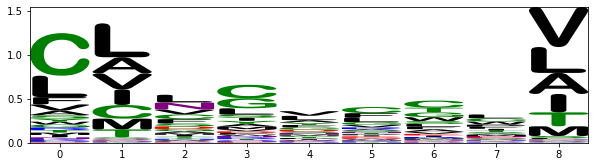

In [71]:
make_logo(top)

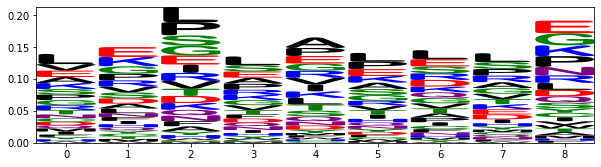

In [72]:
make_logo(bottom)

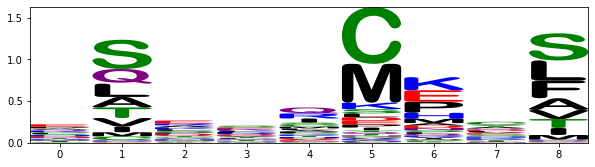

In [73]:
make_logo(bottom_not_inf)

# Top binders. Same analysis

In [74]:
top_percent_binding_value = np.percentile(decoy_data['b_score'].values, 98)
top_percent_binding_value

-22.82061955492968

In [75]:
len(decoy_data[decoy_data['b_score'] > top_percent_binding_value])

8040

In [76]:
selected_decoy_data = decoy_data[decoy_data['b_score'] > top_percent_binding_value].copy()

In [77]:
count = 300
top = selected_decoy_data.sort_values('diff_score', ascending=False)[:count]
bottom = selected_decoy_data.sort_values('diff_score', ascending=True)[:count]
df = selected_decoy_data.sort_values('diff_score', ascending=True)
bottom_not_inf = df[~np.isinf(df['diff_score'])][:count]

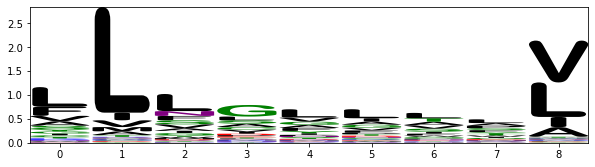

In [78]:
make_logo(top)

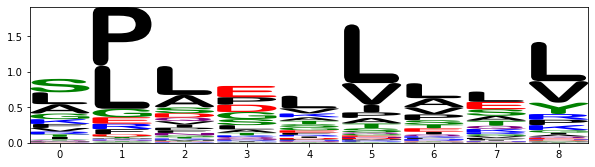

In [79]:
make_logo(bottom)

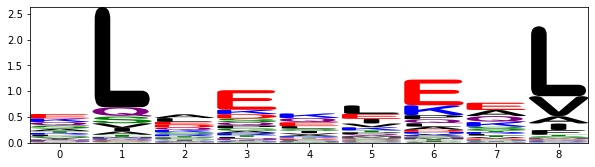

In [80]:
make_logo(bottom_not_inf)

## Same for training data

In [81]:
train_df_repr_db = pivot_data_dict['Train']['db']['mb']
train_df_repr_di = pivot_data_dict['Train']['di']['mb']

In [82]:


train_df_repr_db['b_score'] =  [model_binding.log_probability(peptide) for peptide in train_df_repr_db.index.values]
train_df_repr_di['b_score'] =  [model_binding.log_probability(peptide) for peptide in train_df_repr_di.index.values]

train_df_repr_db['i_score'] =  [model_immunogenic.log_probability(peptide) for peptide in train_df_repr_db.index.values]
train_df_repr_di['i_score'] =  [model_immunogenic.log_probability(peptide) for peptide in train_df_repr_di.index.values]

train_df_repr_db['peptide'] = train_df_repr_db.index.values
train_df_repr_di['peptide'] = train_df_repr_di.index.values

In [83]:
train_df_repr_db['diff_score'] =  train_df_repr_db['i_score'] - train_df_repr_db['b_score']
train_df_repr_db

path_index,0,1,2,3,4,5,6,7,8,9,...,210,211,212,213,214,215,b_score,i_score,peptide,diff_score
peptide,,,,,,,,,,,,,,,,,,,,,
AAAAGRKTL,-32.792101,-35.366215,-32.803943,-35.064798,-28.209427,-30.783541,-28.919583,-31.180438,-32.394328,-34.968442,...,-35.408249,-37.669104,-35.634448,-38.208563,-35.907132,-38.167987,-23.868076,-25.889426,AAAAGRKTL,-2.021350
AAAAGWQTL,-32.853409,-35.427524,-31.739099,-33.999954,-30.942644,-33.516759,-30.526648,-32.787503,-30.754682,-33.328796,...,-37.015315,-39.276169,-33.994802,-36.568916,-33.141333,-35.402188,-24.846314,-25.495647,AAAAGWQTL,-0.649333
AAAAKVPEV,-31.997887,-34.963605,-31.116690,-33.769149,-25.953146,-28.918864,-25.770263,-28.422722,-29.365222,-32.330940,...,-32.979367,-35.631825,-33.325779,-36.291497,-32.705424,-35.357883,-21.250542,-23.211818,AAAAKVPEV,-1.961276
AAAAPRAVA,-34.852652,-36.436108,-34.245294,-35.515491,-30.269978,-31.853434,-30.360934,-31.631131,-34.454879,-36.038336,...,-37.377055,-38.647252,-38.222454,-39.805910,-37.875938,-39.146135,-25.554669,-26.578800,AAAAPRAVA,-1.024131
AAAATCALV,-32.646682,-36.262718,-32.039324,-35.342101,-29.627253,-33.243290,-29.718210,-33.020987,-29.380302,-32.996339,...,-37.596147,-40.898924,-34.009693,-37.625730,-33.663178,-36.965955,-24.112328,-24.854516,AAAATCALV,-0.742188
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YYPTEDVPR,-38.228511,-40.039979,-37.182339,-38.680548,-34.776834,-36.588302,-34.428976,-35.927185,-39.215424,-41.026892,...,-42.506403,-44.004612,-44.044305,-45.855773,-43.258976,-44.757184,-30.655795,-inf,YYPTEDVPR,-inf
YYQNYFEKL,-33.147501,-35.128348,-32.573349,-34.240937,-30.059883,-32.040731,-30.184046,-31.851634,-32.716305,-34.697152,...,-36.416705,-38.084293,-35.700417,-37.681264,-35.387107,-37.054695,-26.476582,-inf,YYQNYFEKL,-inf
YYQSGLSIV,-34.874888,-34.623163,-33.831743,-33.266759,-29.758821,-29.507096,-29.413990,-28.849006,-34.004653,-33.752928,...,-35.731450,-35.166466,-37.073567,-36.821842,-36.291264,-35.726280,-25.338737,-inf,YYQSGLSIV,-inf


In [84]:
train_df_repr_db[['b_score', 'i_score', 'diff_score']].head(10)

path_index,b_score,i_score,diff_score
peptide,,,
AAAAGRKTL,-23.868076,-25.889426,-2.021350
AAAAGWQTL,-24.846314,-25.495647,-0.649333
AAAAKVPEV,-21.250542,-23.211818,-1.961276
AAAAPRAVA,-25.554669,-26.578800,-1.024131
AAAATCALV,-24.112328,-24.854516,-0.742188
AAAAVIPTV,-21.328755,-22.443154,-1.114399
AAADFTAKV,-21.869353,-22.125600,-0.256247
AAADKIPGL,-21.185491,-23.420091,-2.234600
AAADYIPTV,-21.330522,-21.450019,-0.119497


In [85]:
top_500 = train_df_repr_db.sort_values('diff_score', ascending=False)[:500]
bottom_500 = train_df_repr_db.sort_values('diff_score', ascending=True)[:500]
df = train_df_repr_db.sort_values('diff_score', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['diff_score'])][:500]

In [86]:
bottom_500[['b_score', 'i_score', 'diff_score']].head(10)

path_index,b_score,i_score,diff_score
peptide,,,
YYTKGFALL,-25.508717,-inf,-inf
FLLIHQGMH,-29.559964,-inf,-inf
PYTKVEESF,-30.585935,-inf,-inf
FLLMLCLHH,-28.154435,-inf,-inf
PVLLLAALP,-27.660605,-inf,-inf
PVHPPPPGP,-30.051739,-inf,-inf
PVAVALDTK,-28.726030,-inf,-inf
PTSLSLSTP,-28.788838,-inf,-inf
FLLPEVGRG,-24.683276,-inf,-inf


In [87]:
bottom_500_not_inf[['b_score', 'i_score', 'diff_score']].head(10)

path_index,b_score,i_score,diff_score
peptide,,,
KLDIICPKV,-22.447138,-36.156624,-13.709486
GLADRCPAL,-21.492761,-34.732707,-13.239945
VLIRRCHYL,-24.133882,-36.704192,-12.570310
YLFLICHNL,-23.476688,-36.033668,-12.556980
YLLDRCPFL,-21.588428,-33.465864,-11.877436
DIIEQMKGV,-25.939531,-36.392110,-10.452579
WLIEPCKLL,-24.722917,-35.024768,-10.301851
ALSDACKKI,-23.129237,-33.082708,-9.953472
FLRYHCPGL,-25.454931,-35.284486,-9.829555


In [88]:
top_500[['b_score', 'i_score', 'diff_score']].head(10)

path_index,b_score,i_score,diff_score
peptide,,,
CINGVCWTV,-27.833412,-17.938427,9.894985
CINMWCWTV,-32.020409,-22.410174,9.610235
CVNGVCWTV,-27.979639,-18.449253,9.530386
CISGVCWTV,-27.245174,-18.332332,8.912842
CINGACWTV,-28.239486,-19.627840,8.611645
YINGVCWTV,-25.200179,-16.932906,8.267273
CINGVVWTV,-25.666365,-18.641159,7.025206
CINGVCRTV,-27.381861,-20.363854,7.018007
FANCNFTLV,-26.549063,-19.742496,6.806567


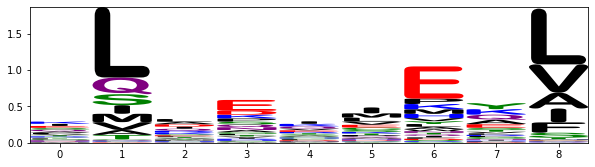

In [89]:
make_logo(bottom_500_not_inf)

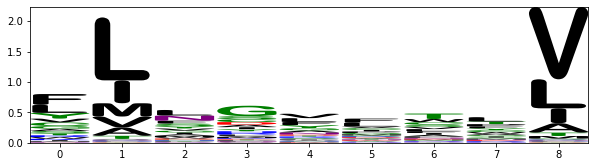

In [90]:
make_logo(top_500)

In [91]:
i_complexity = len(df_i_paths)
b_complexity = len(df_b_paths)

In [92]:
train_df_repr_db['i_score_corrected'] = train_df_repr_db['i_score'] - np.log(i_complexity)
train_df_repr_db['b_score_corrected'] = train_df_repr_db['b_score'] - np.log(b_complexity)
train_df_repr_db['diff_score'] = train_df_repr_db['i_score_corrected'] - train_df_repr_db['b_score_corrected']

In [93]:
top_500 = train_df_repr_db.sort_values('diff_score', ascending=False)[:500]
bottom_500 = train_df_repr_db.sort_values('diff_score', ascending=True)[:500]
df = train_df_repr_db.sort_values('diff_score', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['diff_score'])][:500]

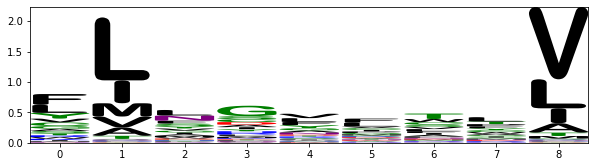

In [94]:
make_logo(top_500)

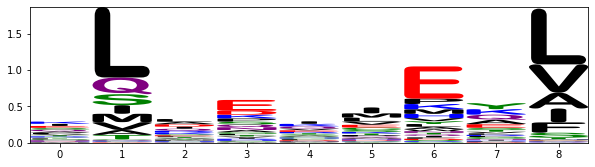

In [95]:
make_logo(bottom_500_not_inf)

In [96]:
top_500

path_index,0,1,2,3,4,5,6,7,8,9,...,212,213,214,215,b_score,i_score,peptide,diff_score,i_score_corrected,b_score_corrected
peptide,,,,,,,,,,,,,,,,,,,,,
CINGVCWTV,-35.740721,-38.314835,-36.342076,-38.602931,-32.721292,-35.295406,-34.020962,-36.281817,-32.474341,-35.048455,...,-31.277268,-33.851382,-32.139466,-34.400320,-27.833412,-17.938427,CINGVCWTV,10.077306,-23.131384,-33.208691
CINMWCWTV,-39.637114,-42.211229,-40.238470,-42.499325,-36.617686,-39.191800,-37.917356,-40.178210,-36.370735,-38.944849,...,-35.848209,-38.422323,-36.710407,-38.971262,-32.020409,-22.410174,CINMWCWTV,9.792557,-27.603131,-37.395688
CVNGVCWTV,-35.886947,-38.461061,-36.488303,-38.749158,-32.867519,-35.441633,-34.167189,-36.428043,-32.620567,-35.194682,...,-31.423495,-33.997609,-32.285692,-34.546547,-27.979639,-18.449253,CVNGVCWTV,9.712707,-23.642210,-33.354917
CISGVCWTV,-37.074186,-39.648300,-37.675541,-39.936396,-34.054757,-36.628871,-35.354427,-37.615282,-33.807806,-36.381920,...,-31.286015,-33.860129,-32.148213,-34.409067,-27.245174,-18.332332,CISGVCWTV,9.095164,-23.525289,-32.620452
CINGACWTV,-35.783685,-38.357799,-36.385040,-38.645895,-32.764256,-35.338370,-34.063926,-36.324781,-32.517305,-35.091419,...,-32.217610,-34.791724,-33.079808,-35.340662,-28.239486,-19.627840,CINGACWTV,8.793967,-24.820797,-33.614764
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SLSGYINYL,-32.509410,-36.811095,-30.865757,-34.854182,-28.090543,-32.392228,-27.145204,-31.133630,-31.687580,-35.989265,...,-30.972068,-35.273753,-29.589257,-33.577682,-20.972677,-18.992016,SLSGYINYL,2.162982,-24.184973,-26.347955
ALNAVRLLV,-29.214847,-32.830883,-29.299310,-32.602087,-24.632173,-28.248209,-25.414950,-28.717727,-28.817074,-32.433110,...,-29.157340,-32.773377,-29.502645,-32.805422,-21.017011,-19.036511,ALNAVRLLV,2.162821,-24.229468,-26.392289
FLVIAINAM,-32.876675,-35.007543,-31.233022,-33.050630,-28.457808,-30.588676,-27.512469,-29.330078,-32.054845,-34.185713,...,-35.058568,-37.189436,-33.675757,-35.493365,-24.594329,-22.615443,FLVIAINAM,2.161208,-27.808400,-29.969608


## Decoy corrected scores

In [97]:
len(decoy_data)

401984

In [98]:
decoy_data['i_score_corrected'] = decoy_data['i_score'] - np.log(i_complexity)
decoy_data['b_score_corrected'] = decoy_data['b_score'] - np.log(b_complexity)
decoy_data['diff_score'] = decoy_data['i_score_corrected'] - decoy_data['b_score_corrected']

In [99]:
sorted_decoy = decoy_data.sort_values('i_score_corrected', ascending=False)

## Difference acros binders

In [100]:
top_percent_binding_value = np.percentile(sorted_decoy['b_score_corrected'].values, 98)
top_percent_binding_value

-28.195897962613845

In [101]:
selected_decoy = sorted_decoy[sorted_decoy['b_score_corrected'] > top_percent_binding_value]

top_500 = selected_decoy.sort_values('diff_score', ascending=False)[:400].copy()
bottom_500 = selected_decoy.sort_values('diff_score', ascending=True)[:400]
df = selected_decoy.sort_values('diff_score', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['diff_score'])][:400].copy()

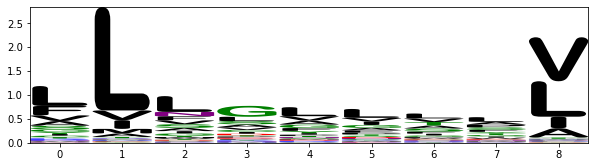

In [102]:
make_logo(top_500)

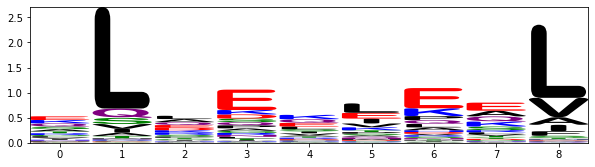

In [103]:
make_logo(bottom_500_not_inf)

## Binding across binders

In [104]:
top_500 = selected_decoy.sort_values('b_score_corrected', ascending=False)[:500]
bottom_500 = selected_decoy.sort_values('b_score_corrected', ascending=True)[:500]
df = selected_decoy.sort_values('b_score_corrected', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['b_score_corrected'])][:500]

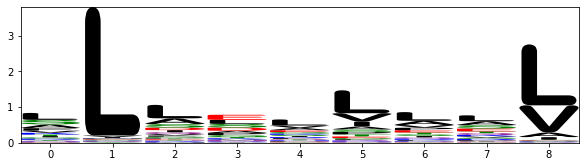

In [105]:
make_logo(top_500)

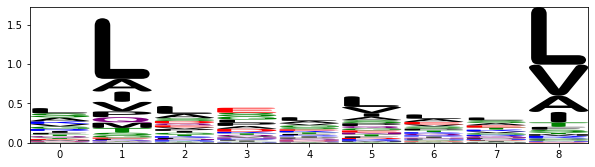

In [106]:
make_logo(bottom_500_not_inf)

## Immunogenicity acros binders

In [107]:
top_500 = selected_decoy.sort_values('i_score_corrected', ascending=False)[:500]
bottom_500 = selected_decoy.sort_values('i_score_corrected', ascending=True)[:500]
df = selected_decoy.sort_values('i_score_corrected', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['i_score_corrected'])][:500]

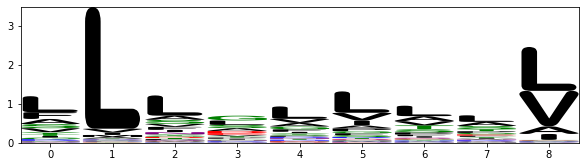

In [108]:
make_logo(top_500)

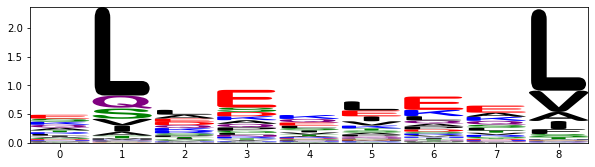

In [109]:
make_logo(bottom_500_not_inf)

## Binding score  across all peptides

In [110]:
top_500 = sorted_decoy.sort_values('b_score_corrected', ascending=False)[:500]
bottom_500 = sorted_decoy.sort_values('b_score_corrected', ascending=True)[:500]
df = sorted_decoy.sort_values('b_score_corrected', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['b_score_corrected'])][:500]

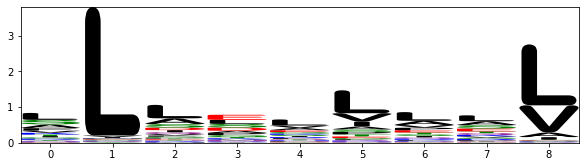

In [111]:
make_logo(top_500)

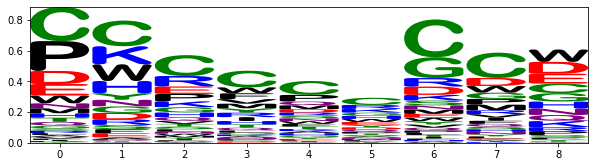

In [112]:
make_logo(bottom_500_not_inf)

## Immunogenicity score across all peptides

In [113]:
top_500 = sorted_decoy.sort_values('i_score_corrected', ascending=False)[:500]
bottom_500 = sorted_decoy.sort_values('i_score_corrected', ascending=True)[:500]
df = sorted_decoy.sort_values('i_score_corrected', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['i_score_corrected'])][:500]

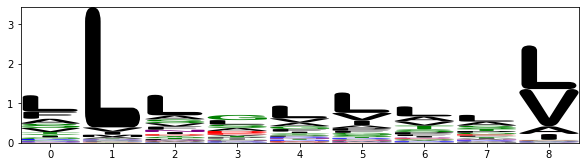

In [114]:
make_logo(top_500)

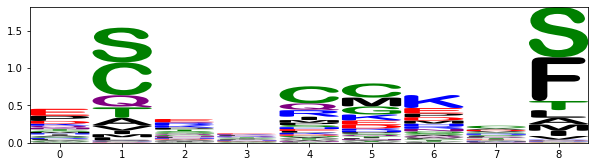

In [115]:
make_logo(bottom_500_not_inf)

## Difference across all peptides

In [116]:
top_500 = sorted_decoy.sort_values('diff_score', ascending=False)[:500]
bottom_500 = sorted_decoy.sort_values('diff_score', ascending=True)[:500]
df = sorted_decoy.sort_values('diff_score', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['diff_score'])][:500]

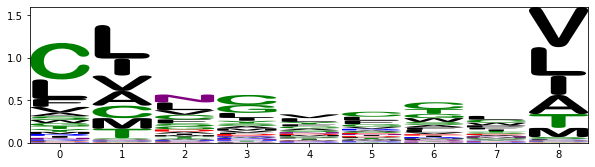

In [117]:
make_logo(top_500)

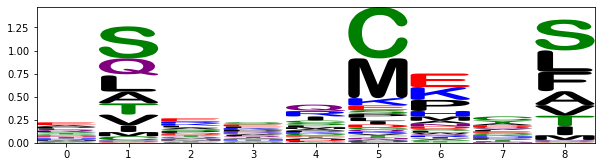

In [118]:
make_logo(bottom_500_not_inf)

## Generated data

In [141]:
len(generated_df_repr_db)

10000

In [142]:
generated_df_repr_db['b_score'] =  [model_binding.log_probability(peptide) for peptide in generated_df_repr_db.index.values]
generated_df_repr_db['peptide'] =  generated_df_repr_db.index.values
generated_df_repr_di['b_score'] =  [model_binding.log_probability(peptide) for peptide in generated_df_repr_di.index.values]
generated_df_repr_di['peptide'] =  generated_df_repr_di.index.values

generated_df_repr_db['i_score'] =  [model_immunogenic.log_probability(peptide) for peptide in generated_df_repr_db.index.values]
generated_df_repr_di['i_score'] =  [model_immunogenic.log_probability(peptide) for peptide in generated_df_repr_di.index.values]


generated_df_repr_db.head()

path_index,0,1,2,3,4,5,6,7,8,9,...,209,210,211,212,213,214,215,b_score,peptide,i_score
peptide,,,,,,,,,,,,,,,,,,,,,
AAAEVDEKL,-30.733741,-32.714588,-30.159589,-31.827177,-27.282063,-29.262911,-27.406226,-29.073814,-31.720654,-33.701502,...,-34.063025,-32.206341,-33.873929,-33.272223,-35.253070,-32.958913,-34.626501,-22.304836,AAAEVDEKL,-27.748956
AAAKSITTV,-30.608998,-33.183112,-31.264002,-33.524857,-26.190131,-28.764245,-27.543449,-29.804304,-29.787168,-32.361282,...,-34.914897,-33.694101,-35.954956,-32.689274,-35.263388,-33.605120,-35.865975,-21.990744,AAAKSITTV,-23.204065
AADDVLNLI,-33.743556,-37.359592,-32.099903,-35.402680,-28.627489,-32.243525,-27.682150,-30.984927,-32.873321,-36.489357,...,-35.761260,-31.199885,-34.502662,-33.142510,-36.758546,-31.759699,-35.062476,-22.687498,AADDVLNLI,-23.857011
AADDVLYYL,-31.975246,-36.276931,-32.263385,-36.251810,-26.859179,-31.160864,-27.845632,-31.834057,-31.105011,-35.406696,...,-34.678599,-31.363367,-35.351792,-31.374200,-35.675885,-31.923181,-35.911606,-21.921384,AADDVLYYL,-22.553491
AAEELPIRT,-30.277363,-32.308234,-31.984827,-33.702438,-27.790271,-29.821142,-30.196049,-31.913661,-29.189687,-31.220558,...,-36.196208,-36.571116,-38.288727,-32.316208,-34.347078,-34.284514,-36.002125,-25.585308,AAEELPIRT,-27.666379


In [160]:
top_500 = generated_df_repr_db.sort_values('i_score', ascending=False)[:500]
bottom_500 = generated_df_repr_db.sort_values('i_score', ascending=True)[:500]
df = generated_df_repr_db.sort_values('i_score', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['i_score'])][:500]

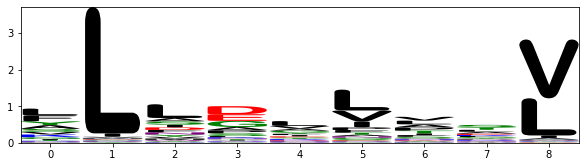

In [161]:
make_logo(top_500)

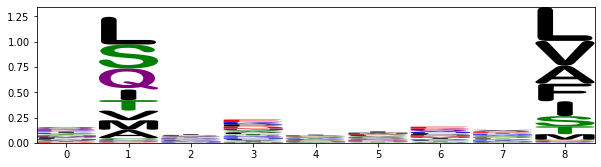

In [162]:
make_logo(bottom_500_not_inf)

In [157]:
df

path_index,0,1,2,3,4,5,6,7,8,9,...,209,210,211,212,213,214,215,b_score,peptide,i_score
peptide,,,,,,,,,,,,,,,,,,,,,
MLCEACNIH,-40.554963,-40.303238,-38.911310,-38.346326,-37.535534,-37.283810,-36.590195,-36.025212,-37.288583,-37.036859,...,-42.402735,-41.709121,-41.144137,-39.158963,-38.907238,-37.776152,-37.211168,-31.474671,MLCEACNIH,-inf
HLPIYNCVP,-38.239025,-39.822481,-37.260678,-38.530875,-34.949125,-36.532581,-34.669092,-35.939289,-37.096758,-38.680215,...,-41.499955,-39.636466,-40.906663,-38.815586,-40.399042,-38.098081,-39.368278,-30.799537,HLPIYNCVP,-inf
WLIWSGWSP,-37.655001,-40.469180,-38.256356,-40.757276,-34.713577,-37.527755,-36.013247,-38.514166,-35.559099,-38.373278,...,-40.913563,-39.399054,-41.899974,-35.696361,-38.510540,-36.558559,-39.059478,-30.554983,WLIWSGWSP,-inf
MLFYWYMFA,-39.243714,-42.000400,-37.286662,-39.730089,-35.708185,-38.464871,-34.449447,-36.892874,-37.410189,-40.166875,...,-42.891146,-38.875722,-41.319148,-38.587918,-41.344604,-36.891707,-39.335134,-29.510344,MLFYWYMFA,-27.414184
RLNWVPCIM,-38.306686,-38.054961,-37.328339,-36.763355,-35.819594,-35.567870,-35.539561,-34.974577,-37.219011,-36.967286,...,-38.097747,-38.069439,-37.504455,-36.500342,-36.248617,-35.782837,-35.217853,-29.490160,RLNWVPCIM,-28.086467
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
LLLDLVVKL,-27.543157,-29.524005,-26.496986,-28.164574,-21.498416,-23.479263,-21.150559,-22.818147,-24.910492,-26.891339,...,-31.080701,-28.751996,-30.419584,-29.263383,-31.244231,-28.478053,-30.145641,-17.527521,LLLDLVVKL,-16.773777
FLLEGLPKL,-25.997523,-27.978371,-25.116327,-26.783915,-20.881456,-22.862304,-20.698574,-22.366162,-25.127288,-27.108136,...,-29.761314,-27.597585,-29.265173,-28.777753,-30.758600,-28.157398,-29.824986,-17.526491,FLLEGLPKL,-17.456550
ILLELVVTV,-26.569675,-29.143789,-25.523503,-27.784358,-20.524934,-23.099048,-20.177076,-22.437931,-23.937009,-26.511124,...,-29.511931,-26.589960,-28.850815,-27.101347,-29.675461,-26.316017,-28.576872,-17.502205,ILLELVVTV,-17.512200
